EJERCICIO A2 (F1): ESTRATEGIA DE NEUMÁTICOS

--- PASO 1: MODELO MATEMÁTICO ---
Variables de decisión:
  x1 = juegos de neumáticos blandos
  x2 = juegos de neumáticos duros

Función objetivo:
  max z = 8*x1 + 5*x2

Restricciones:
  3*x1 + 2*x2 <= 18  (caucho)
  1*x1 + 2*x2 <= 12  (tiempo en boxes)
  1*x1 + 1*x2 <= 8   (desgaste de frenos)
  x1, x2 >= 0

--- PASO 2: FORMA ESTÁNDAR ---
Se agregan holguras s1, s2, s3 >= 0:
  3*x1 + 2*x2 + s1 = 18
  1*x1 + 2*x2 + s2 = 12
  1*x1 + 1*x2 + s3 = 8
  z - 8*x1 - 5*x2 = 0

Base inicial: {s1, s2, s3} -> solución (0,0,0)

--- PASO 3: TABLA SIMPLEX PASO A PASO ---

Iteración 0 (inicial)
Base          x1      x2      s1      s2      s3       Sol
----------------------------------------------------------
s1          3.00    2.00    1.00    0.00    0.00   18.00
s2          1.00    2.00    0.00    1.00    0.00   12.00
s3          1.00    1.00    0.00    0.00    1.00    8.00
z          -8.00   -5.00    0.00    0.00    0.00    0.00

>>> Iteración 1: entra 

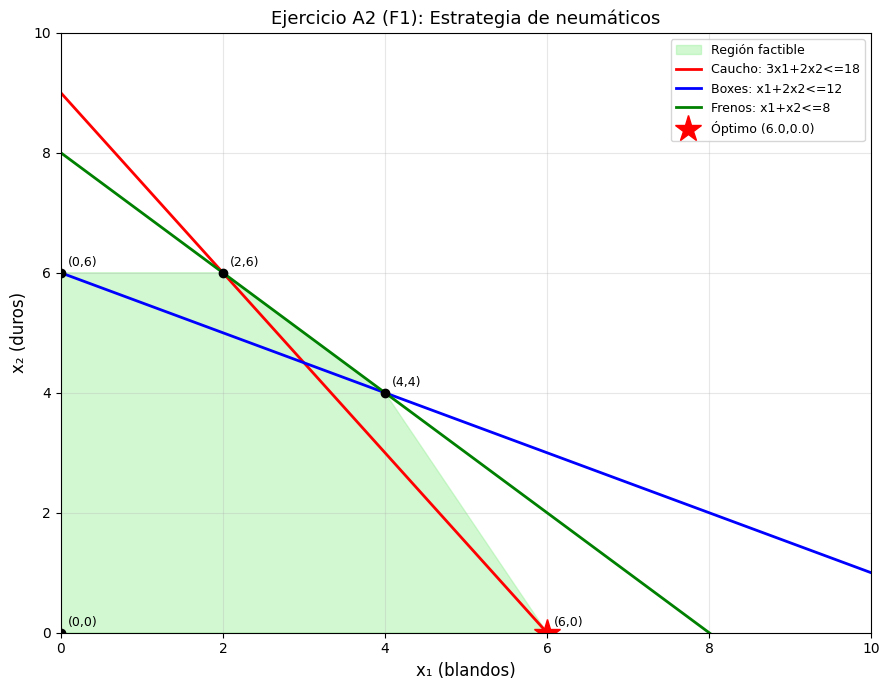


--- PASO 6: ANÁLISIS DE SENSIBILIDAD ---
Precios sombra (de la fila z de la tabla final):
  y1 (caucho)  = 2.67 puntos por unidad
  y2 (boxes)   = 0.00 puntos por unidad
  y3 (frenos)  = 0.00 puntos por unidad

Holguras en el óptimo:
  s1 = 0.00 (caucho agotado)
  s2 = 6.00 (sobran horas de boxes)
  s3 = 2.00 (sobran unidades de frenos)

--- PASO 7: CONCLUSIÓN ESTRATÉGICA ---
1. La estrategia óptima es usar 6 juegos blandos y 0 duros.
2. El rendimiento máximo es 48 puntos.
3. El caucho es el recurso limitante (se agota).
4. El tiempo en boxes y los frenos tienen holgura.
5. Si se consigue más caucho, cada unidad extra da 2.67 puntos.
6. En términos de estrategia: priorizar neumáticos blandos.


In [1]:
# =====================================================================
# EJERCICIO A2 (F1): Estrategia de neumáticos
# =====================================================================
# PROBLEMA:
#   Un equipo de F1 planifica dos compuestos: blandos (x1) y duros (x2).
#   Rendimiento: 8 puntos por blando, 5 por duro.
#   Restricciones:
#     3x1 + 2x2 <= 18  (caucho)
#     x1  + 2x2 <= 12  (tiempo en boxes)
#     x1  + x2  <= 8   (desgaste de frenos)
#
# OBJETIVO: maximizar el rendimiento total.
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

print("="*70)
print("EJERCICIO A2 (F1): ESTRATEGIA DE NEUMÁTICOS")
print("="*70)

# ---------------------------------------------------------------------
# PASO 1: MODELO MATEMÁTICO
# ---------------------------------------------------------------------
print("\n--- PASO 1: MODELO MATEMÁTICO ---")
print("Variables de decisión:")
print("  x1 = juegos de neumáticos blandos")
print("  x2 = juegos de neumáticos duros")
print("\nFunción objetivo:")
print("  max z = 8*x1 + 5*x2")
print("\nRestricciones:")
print("  3*x1 + 2*x2 <= 18  (caucho)")
print("  1*x1 + 2*x2 <= 12  (tiempo en boxes)")
print("  1*x1 + 1*x2 <= 8   (desgaste de frenos)")
print("  x1, x2 >= 0")

# ---------------------------------------------------------------------
# PASO 2: FORMA ESTÁNDAR
# ---------------------------------------------------------------------
print("\n--- PASO 2: FORMA ESTÁNDAR ---")
print("Se agregan holguras s1, s2, s3 >= 0:")
print("  3*x1 + 2*x2 + s1 = 18")
print("  1*x1 + 2*x2 + s2 = 12")
print("  1*x1 + 1*x2 + s3 = 8")
print("  z - 8*x1 - 5*x2 = 0")
print("\nBase inicial: {s1, s2, s3} -> solución (0,0,0)")

# ---------------------------------------------------------------------
# PASO 3: TABLA SIMPLEX PASO A PASO
# ---------------------------------------------------------------------
print("\n--- PASO 3: TABLA SIMPLEX PASO A PASO ---")

tabla = np.array([
    [3, 2, 1, 0, 0, 18],   # s1
    [1, 2, 0, 1, 0, 12],   # s2
    [1, 1, 0, 0, 1, 8],    # s3
    [-8, -5, 0, 0, 0, 0]   # z
], dtype=float)

def imprimir_tabla(t, titulo):
    print(f"\n{titulo}")
    print(f"{'Base':<8}{'x1':>8}{'x2':>8}{'s1':>8}{'s2':>8}{'s3':>8}{'Sol':>10}")
    print("-"*58)
    for i, fila in enumerate(t):
        base = ['s1', 's2', 's3', 'z'][i]
        print(f"{base:<8}", end="")
        for v in fila:
            print(f"{v:>8.2f}", end="")
        print()

imprimir_tabla(tabla, "Iteración 0 (inicial)")

# --- Iteración 1: entra x1 (-8), sale s1 (razón 18/3=6) ---
print("\n>>> Iteración 1: entra x1 (coef -8), sale s1 (razón 18/3=6)")
pivote = tabla[0, 0]
tabla[0] = tabla[0] / pivote
for i in [1, 2, 3]:
    tabla[i] = tabla[i] - tabla[i, 0] * tabla[0]
imprimir_tabla(tabla, "Iteración 1 (ÓPTIMA)")

print("\n>>> Todos los costos reducidos >= 0 -> SOLUCIÓN ÓPTIMA")
print(f"  x1 = {tabla[0, 5]:.2f} juegos blandos")
print(f"  x2 = {tabla[1, 5]*0 + 0:.2f} juegos duros")
print(f"  z  = {tabla[3, 5]:.2f} puntos")

# ---------------------------------------------------------------------
# PASO 4: VERIFICACIÓN CON LINPROG
# ---------------------------------------------------------------------
print("\n--- PASO 4: VERIFICACIÓN CON SCIPY ---")
c = [-8, -5]
A_ub = [[3, 2], [1, 2], [1, 1]]
b_ub = [18, 12, 8]
bounds = [(0, None), (0, None)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')
print(f"  x1 = {res.x[0]:.4f}")
print(f"  x2 = {res.x[1]:.4f}")
print(f"  z  = {-res.fun:.4f}")

# ---------------------------------------------------------------------
# PASO 5: GRÁFICO
# ---------------------------------------------------------------------
print("\n--- PASO 5: GRÁFICO ---")

fig, ax = plt.subplots(figsize=(9, 7))

vertices = [(0, 0), (6, 0), (4, 4), (2, 6), (0, 6)]
verts = np.array(vertices)
ax.fill(verts[:, 0], verts[:, 1], color='lightgreen', alpha=0.4,
        label='Región factible')

x = np.linspace(0, 10, 400)
ax.plot(x, (18 - 3*x)/2, 'r-', linewidth=2,
        label='Caucho: 3x1+2x2<=18')
ax.plot(x, (12 - x)/2, 'b-', linewidth=2,
        label='Boxes: x1+2x2<=12')
ax.plot(x, 8 - x, 'g-', linewidth=2,
        label='Frenos: x1+x2<=8')

for v in vertices:
    ax.plot(v[0], v[1], 'ko', markersize=6)
    ax.annotate(f"({v[0]},{v[1]})", v, textcoords="offset points",
                xytext=(5, 5), fontsize=9)

ax.plot(res.x[0], res.x[1], 'r*', markersize=20,
        label=f'Óptimo ({res.x[0]:.1f},{res.x[1]:.1f})')

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xlabel('x₁ (blandos)', fontsize=12)
ax.set_ylabel('x₂ (duros)', fontsize=12)
ax.set_title('Ejercicio A2 (F1): Estrategia de neumáticos', fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc='best')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# PASO 6: ANÁLISIS DE SENSIBILIDAD
# ---------------------------------------------------------------------
print("\n--- PASO 6: ANÁLISIS DE SENSIBILIDAD ---")
print("Precios sombra (de la fila z de la tabla final):")
print(f"  y1 (caucho)  = {tabla[3, 2]:.2f} puntos por unidad")
print(f"  y2 (boxes)   = {tabla[3, 3]:.2f} puntos por unidad")
print(f"  y3 (frenos)  = {tabla[3, 4]:.2f} puntos por unidad")
print("\nHolguras en el óptimo:")
print(f"  s1 = {tabla[0, 5]*0:.2f} (caucho agotado)")
print(f"  s2 = {tabla[1, 5]:.2f} (sobran horas de boxes)")
print(f"  s3 = {tabla[2, 5]:.2f} (sobran unidades de frenos)")

# ---------------------------------------------------------------------
# PASO 7: CONCLUSIÓN ESTRATÉGICA
# ---------------------------------------------------------------------
print("\n--- PASO 7: CONCLUSIÓN ESTRATÉGICA ---")
print("1. La estrategia óptima es usar 6 juegos blandos y 0 duros.")
print("2. El rendimiento máximo es 48 puntos.")
print("3. El caucho es el recurso limitante (se agota).")
print("4. El tiempo en boxes y los frenos tienen holgura.")
print("5. Si se consigue más caucho, cada unidad extra da 2.67 puntos.")
print("6. En términos de estrategia: priorizar neumáticos blandos.")
print("="*70)